In [1]:
from graphdatascience import GraphDataScience
import pandas as pd
import matplotlib.pyplot as plt

gds = GraphDataScience("bolt://localhost:7687", auth=("neo4j", "Lastfm_2026_pw"))
print(gds.server_version())
print(gds.run_cypher("MATCH (n) RETURN count(n) AS nodes"))

Matplotlib is building the font cache; this may take a moment.


2.13.15
   nodes
0  19914


In [2]:
G, res = gds.graph.project.native(
    "listen", ["User", "Artist"],
    {"LISTEN_TO": {"orientation": "UNDIRECTED", "properties": "weight"}},
    overwrite=True)
print("projection:", G.node_count(), G.relationship_count())

projection: 19914 185668


In [3]:
deg = gds.degree_centrality.stream(G)
lab = gds.run_cypher("MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label, n.id AS id")
deg = deg.merge(lab, on="nodeId")
deg = deg[deg.score > 0]          # drops the 390 artists with no listens

for l in ["User", "Artist"]:
    s = deg[deg.label == l]["score"]
    print(l, "count", len(s), "mean", round(s.mean(), 2), "median", s.median(), "max", s.max())
print(deg.sort_values("score", ascending=False).head(10))

Received notification from DBMS server: <GqlStatusObject gql_status='01N02', status_description='warn: feature deprecated without replacement. id is deprecated and will be removed without a replacement.', position=<SummaryInputPosition line=1, column=18, offset=17>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 17, 'line': 1, 'column': 18}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label, n.id AS id'


User count 1892 mean 49.07 median 50.0 max 50.0
Artist count 17632 mean 5.27 median 1.0 max 611.0
      nodeId  score   label     id
1930    1930  611.0  Artist  10089
2130    2130  522.0  Artist  10289
2129    2129  484.0  Artist  10288
2068    2068  480.0  Artist  10227
2141    2141  473.0  Artist  10300
1908    1908  429.0  Artist  10067
2174    2174  417.0  Artist  10333
2133    2133  407.0  Artist  10292
2031    2031  400.0  Artist  10190
2340    2340  399.0  Artist  10498


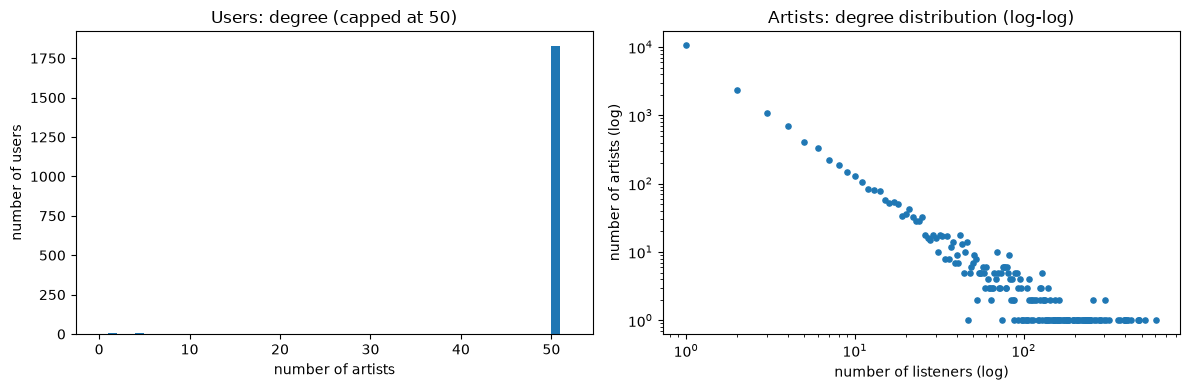

artists with exactly 1 listener: 60.6 %
top 1% of artists ( 176 ) hold 31.6 % of all listen links
top 10% of artists hold 70.0 % of all listen links


In [4]:
art = deg[deg.label == "Artist"]["score"]
usr = deg[deg.label == "User"]["score"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(usr, bins=range(0, 53))
ax[0].set_title("Users: degree (capped at 50)")
ax[0].set_xlabel("number of artists"); ax[0].set_ylabel("number of users")

counts = art.value_counts().sort_index()
ax[1].scatter(counts.index, counts.values, s=14)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Artists: degree distribution (log-log)")
ax[1].set_xlabel("number of listeners (log)"); ax[1].set_ylabel("number of artists (log)")
plt.tight_layout(); plt.show()

a = art.sort_values(ascending=False)
total = a.sum()
print("artists with exactly 1 listener:", round((a == 1).mean() * 100, 1), "%")
print("top 1% of artists (", int(len(a)*0.01), ") hold", round(a.head(int(len(a)*0.01)).sum()/total*100, 1), "% of all listen links")
print("top 10% of artists hold", round(a.head(int(len(a)*0.10)).sum()/total*100, 1), "% of all listen links")

In [5]:
art_names = pd.read_csv("data/artists.dat", sep="\t", encoding="utf-8", quoting=3)
print(art_names.shape)
print(art_names.head())

(17632, 4)
   id               name                                         url  \
0   1       MALICE MIZER       http://www.last.fm/music/MALICE+MIZER   
1   2    Diary of Dreams    http://www.last.fm/music/Diary+of+Dreams   
2   3  Carpathian Forest  http://www.last.fm/music/Carpathian+Forest   
3   4       Moi dix Mois       http://www.last.fm/music/Moi+dix+Mois   
4   5        Bella Morte        http://www.last.fm/music/Bella+Morte   

                                          pictureURL  
0    http://userserve-ak.last.fm/serve/252/10808.jpg  
1  http://userserve-ak.last.fm/serve/252/3052066.jpg  
2  http://userserve-ak.last.fm/serve/252/40222717...  
3  http://userserve-ak.last.fm/serve/252/54697835...  
4  http://userserve-ak.last.fm/serve/252/14789013...  


In [8]:
# 1. erase the wrong names
gds.run_cypher("MATCH (a:Artist) REMOVE a.name")

# 2. reload with the +10000 offset
rows = [{"rawId": int(i) + 10000, "name": n}
        for i, n in zip(art_names["id"], art_names["name"].fillna(""))]
gds.run_cypher("UNWIND $rows AS r MATCH (a:Artist {rawId: r.rawId}) SET a.name = r.name",
               {"rows": rows})

print(gds.run_cypher("MATCH (a:Artist) RETURN count(a) AS total, count(a.name) AS withName"))

   total  withName
0  18022     17632


In [9]:
names = gds.run_cypher("MATCH (a:Artist) RETURN id(a) AS nodeId, a.name AS name")
top = (deg[deg.label == "Artist"].merge(names, on="nodeId")
          .sort_values("score", ascending=False).head(10)[["name", "score"]])
print(top.to_string(index=False))

Received notification from DBMS server: <GqlStatusObject gql_status='01N02', status_description='warn: feature deprecated without replacement. id is deprecated and will be removed without a replacement.', position=<SummaryInputPosition line=1, column=25, offset=24>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 24, 'line': 1, 'column': 25}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (a:Artist) RETURN id(a) AS nodeId, a.name AS name'


              name  score
         Lady Gaga  611.0
    Britney Spears  522.0
           Rihanna  484.0
       The Beatles  480.0
        Katy Perry  473.0
           Madonna  429.0
     Avril Lavigne  417.0
Christina Aguilera  407.0
              Muse  400.0
          Paramore  399.0


- Top-10 artists by degree: Lady Gaga (611), Britney Spears (522), Rihanna (484),
  The Beatles (480), Katy Perry (473), Madonna (429), Avril Lavigne (417),
  Christina Aguilera (407), Muse (400), Paramore (399).
  Interpretation: hubs are mainstream pop artists known to everyone, so a
  popularity-based recommender would keep suggesting the same names.
- Note: GDS artist rawId = original artists.dat id + 10000, so names are joined with that offset.
  Check: the top hubs match the well-known most-listened artists of the dataset.

In [11]:
wcc = gds.wcc.stream(G)
wcc = wcc.merge(lab_all := gds.run_cypher("MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label, n.id AS id"), on="nodeId")
sizes = wcc.groupby("componentId").size().sort_values(ascending=False)
print("components (incl. 390 isolated artists):", len(sizes))
print("largest component:", sizes.iloc[0], "nodes =", round(sizes.iloc[0]/len(wcc)*100, 2), "%")
print(sizes.head(10))

 WCC:  15%|#5        | 15.28/100 [00:00<?, ?%/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N02', status_description='warn: feature deprecated without replacement. id is deprecated and will be removed without a replacement.', position=<SummaryInputPosition line=1, column=18, offset=17>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 17, 'line': 1, 'column': 18}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label, n.id AS id'


components (incl. 390 isolated artists): 398
largest component: 19507 nodes = 97.96 %
componentId
0        19507
1708         5
571          2
1878         2
1584         2
1562         2
1447         2
107          2
19642        1
19832        1
dtype: int64


In [12]:
print("components with >1 node:", (sizes > 1).sum())

components with >1 node: 8


In [13]:
import networkx as nx, random
edges = gds.run_cypher("MATCH (u:User)-[:LISTEN_TO]->(a:Artist) RETURN u.id AS u, a.id AS a")
Gx = nx.Graph()
Gx.add_edges_from(zip(("u%d" % x for x in edges.u), ("a%d" % x for x in edges.a)))
print("nodes:", Gx.number_of_nodes(), "edges:", Gx.number_of_edges())
print("connected:", nx.is_connected(Gx))

random.seed(42)
sample = random.sample(list(Gx.nodes()), 300)
dists = []
ecc = []
for s in sample:
    d = nx.single_source_shortest_path_length(Gx, s)
    dists.extend(v for k, v in d.items() if k != s)
    ecc.append(max(d.values()))
print("average shortest path (300 sampled sources):", round(sum(dists)/len(dists), 2))
print("diameter lower bound (max eccentricity found):", max(ecc))
print(pd.Series(dists).value_counts().sort_index())

nodes: 19524 edges: 92834
connected: False
average shortest path (300 sampled sources): 4.56
diameter lower bound (max eccentricity found): 10
1        3091
2       83762
3      693883
4     2784515
5      432946
6     1835187
7        2105
8       16202
9           7
10        102
Name: count, dtype: int64


In [14]:
fr = gds.run_cypher("MATCH (a:User)-[:IS_FRIEND]->(b:User) RETURN a.id AS a, b.id AS b")
Gf = nx.Graph(); Gf.add_edges_from(zip(fr.a, fr.b))
cc = sorted(nx.connected_components(Gf), key=len, reverse=True)
print("friend graph: nodes", Gf.number_of_nodes(), "edges", Gf.number_of_edges(), "components", len(cc), "largest", len(cc[0]))

friend graph: nodes 1892 edges 12717 components 20 largest 1843


In [15]:
print("=== Q5 SUMMARY ===")
print("projection nodes:", len(wcc))
print("components total:", len(sizes))
print("components with >1 node:", int((sizes > 1).sum()))
print("largest component:", int(sizes.iloc[0]), "nodes =", round(sizes.iloc[0]/len(wcc)*100, 2), "%")
print("listening graph (networkx) nodes:", Gx.number_of_nodes(), "edges:", Gx.number_of_edges(), "connected:", nx.is_connected(Gx))
print("average shortest path (300 sources):", round(sum(dists)/len(dists), 2))
print("diameter lower bound:", max(ecc))
print("distance counts:"); print(pd.Series(dists).value_counts().sort_index().to_string())
print("friend graph: nodes", Gf.number_of_nodes(), "edges", Gf.number_of_edges(), "components", len(cc), "largest", len(cc[0]))

=== Q5 SUMMARY ===
projection nodes: 19914
components total: 398
components with >1 node: 8
largest component: 19507 nodes = 97.96 %
listening graph (networkx) nodes: 19524 edges: 92834 connected: False
average shortest path (300 sources): 4.56
diameter lower bound: 10
distance counts:
1        3091
2       83762
3      693883
4     2784515
5      432946
6     1835187
7        2105
8       16202
9           7
10        102
friend graph: nodes 1892 edges 12717 components 20 largest 1843


In [16]:
from math import comb

# projection of the friendship layer (undirected)
Gf_gds, _ = gds.graph.project.native("friends", ["User"],
    {"IS_FRIEND": {"orientation": "UNDIRECTED"}}, overwrite=True)
print("friends projection:", Gf_gds.node_count(), Gf_gds.relationship_count())

tri = gds.triangle_count.stream(Gf_gds)
print(tri.columns.tolist())
tri_col = [c for c in tri.columns if "riangle" in c][0]
total_triangles = int(tri[tri_col].sum() // 3)
print("triangles:", total_triangles)

lcc = gds.local_clustering_coefficient.stream(Gf_gds)
print(lcc.columns.tolist())
lcc_col = [c for c in lcc.columns if "lustering" in c][0]
print("average clustering coefficient:", round(lcc[lcc_col].mean(), 4))

n, m = Gf_gds.node_count(), 12717
p = 2*m / (n*(n-1))
expected = comb(n, 3) * p**3
print("random graph: p =", round(p, 5), " expected triangles =", round(expected, 1))
print("ratio real / random:", round(total_triangles / expected, 1))
print("random graph expected clustering ~ p =", round(p, 5))

 Loading:   0%|          | 0.0/100 [00:00<?, ?%/s]

friends projection: 1892 25434
['nodeId', 'triangleCount']
triangles: 19690
['nodeId', 'localClusteringCoefficient']
average clustering coefficient: 0.1865
random graph: p = 0.00711  expected triangles = 404.9
ratio real / random: 48.6
random graph expected clustering ~ p = 0.00711


In [17]:
bw = gds.betweenness.stream(G, sampling_size=2000, sampling_seed=42)
bw = bw.merge(
    gds.run_cypher("""MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label,
                      n.id AS id, n.name AS name"""),
    on="nodeId")
bw = bw.merge(deg[["nodeId", "score"]].rename(columns={"score": "degree"}), on="nodeId", how="left")

top_bw = bw.sort_values("score", ascending=False).head(10)
print(top_bw[["label", "name", "id", "score", "degree"]].to_string(index=False))

# overlap with the top-10 by degree
top_deg_ids = set(deg.sort_values("score", ascending=False).head(10)["nodeId"])
top_bw_ids = set(top_bw["nodeId"])
print("overlap top-10 degree vs top-10 betweenness:", len(top_deg_ids & top_bw_ids), "of 10")

# correlation between the two rankings
print("rank correlation (Spearman):", round(bw[["score", "degree"]].dropna().corr(method="spearman").iloc[0, 1], 3))

# top 10 users by betweenness, separately
print(bw[bw.label == "User"].sort_values("score", ascending=False).head(10)[["id", "score", "degree"]].to_string(index=False))

 Betweenness Centrality:   0%|          | 0.2/100 [00:00<?, ?%/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N02', status_description='warn: feature deprecated without replacement. id is deprecated and will be removed without a replacement.', position=<SummaryInputPosition line=1, column=18, offset=17>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 17, 'line': 1, 'column': 18}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH (n) RETURN id(n) AS nodeId, labels(n)[0] AS label,\n                      n.id AS id, n.name AS name'


 label           name    id        score  degree
Artist    The Beatles 10227 1.061108e+06   480.0
Artist      Lady Gaga 10089 8.998555e+05   611.0
Artist      Radiohead 10154 7.101433e+05   393.0
Artist           Muse 10190 5.178997e+05   400.0
Artist   Depeche Mode 10072 4.745469e+05   282.0
Artist        Madonna 10067 4.416453e+05   429.0
Artist       Coldplay 10065 4.362099e+05   369.0
Artist Britney Spears 10289 3.904271e+05   522.0
Artist       Paramore 10498 3.459755e+05   399.0
Artist     Pink Floyd 10163 3.088056e+05   258.0
overlap top-10 degree vs top-10 betweenness: 6 of 10
rank correlation (Spearman): 0.989
 id         score  degree
  3 255065.519389    50.0
 16 184313.990936    50.0
 39 143362.435565    50.0
 55 127813.946628    50.0
 53 113550.934126    50.0
 52 111173.898140    50.0
 14 110131.736544    50.0
 48  99662.694558    50.0
 20  91531.553799    50.0
 26  79102.501080    50.0


In [18]:
import os
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
def keep(name, fn):
    try: fn(); print("saved", name)
    except Exception as ex: print("SKIPPED", name, "->", type(ex).__name__, ex)

keep("degree",      lambda: deg.to_csv("results/b_degree.csv", index=False))
keep("betweenness", lambda: bw.to_csv("results/b_betweenness.csv", index=False))
keep("components",  lambda: wcc.to_csv("results/b_components.csv", index=False))
keep("distances",   lambda: pd.Series(dists).value_counts().sort_index().rename_axis("distance").reset_index(name="pairs").to_csv("results/b_distance_counts.csv", index=False))
keep("triangles",   lambda: tri.to_csv("results/b_triangles_per_user.csv", index=False))
keep("clustering",  lambda: lcc.to_csv("results/b_clustering_per_user.csv", index=False))
keep("top10 names", lambda: top.to_csv("results/b_top10_degree_names.csv", index=False))

def fig_degree():
    a_ = deg[deg.label == "Artist"].score; u_ = deg[deg.label == "User"].score
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(u_, bins=range(0, 53)); ax[0].set_title("Users: degree (capped at 50)")
    c = a_.value_counts().sort_index(); ax[1].scatter(c.index, c.values, s=14)
    ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_title("Artists: degree distribution (log-log)")
    ax[1].set_xlabel("listeners"); ax[1].set_ylabel("artists")
    plt.tight_layout(); plt.savefig("figures/b_degree_distribution.png", dpi=200); plt.close()
keep("figure degree", fig_degree)

def fig_dist():
    dc = pd.Series(dists).value_counts().sort_index()
    plt.figure(figsize=(6, 4)); plt.bar(dc.index, dc.values); plt.title("Sampled shortest-path lengths")
    plt.xlabel("distance"); plt.ylabel("pairs"); plt.tight_layout(); plt.savefig("figures/b_distances.png", dpi=200); plt.close()
keep("figure distances", fig_dist)

saved degree
saved betweenness
saved components
saved distances
saved triangles
saved clustering
saved top10 names
saved figure degree
saved figure distances
